## **MScFE 690 Capstone Project - Group 17836**
## **_"Dynamic Cross-Asset Replication of the S&P/ASX 200 VIX: Factor-Based and Regime-Aware ETF Portfolios"_**


In [1]:
import importlib.util
import itertools
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
import yfinance as yf
import seaborn as sns
import warnings
import cvxpy as cp

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNetCV

from hmmlearn import hmm

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)


warnings.filterwarnings("ignore")

SEED =2026

PLOT_GRAPH = True

START_DATE = "2011-01-01"
END_DATE   = "2026-09-15"

TRANSACTION_COST = 0.001  # 0.1% electronic trading , slippage and bid-ask spread
SHORT_BORROW_RATE = 0.0025 # 0.25% borrowing rate to short Sector & Thematic ETFs

# Fady: be tuned
TRN_WINDOW = 252
TST_WINDOW = 10
HMM_STATES = 3
MIN_ABS_WEIGHT = 0.01 
WEIGHT_DEVIATION = 0.05
N_COMPONENTS = 5


PLT_STRT = 0
PLT_SIZE = 4000
MIN_REL_WEIGHT_CHANGE = 0.01


### **Overview**
As part of our M2 project proposal submission, we outlined the code high level design steps which can be summarised as follows:
1. Data processing
2. Screening and elimination
3. Sliding window Walk-forward loop:

    3.1 Sliding window Walk-forward loop: Principal Component Regression (PCR)
   
    3.2 Sliding window Walk-forward loop: Partial Least Squares (PLS)
   
    3.3 Sliding window Walk-forward loop: Elastic Net Regression (EN)
   
5. Hidden Markov Model
6. Expanding window Walk-forward loop for HMM

In the next sections we will outline and implement each of these steps in details.

In [2]:
# Fady: Define reusable util functions

def walk_forward_sliding_window(dataset_length, train_window_size, test_window_size):
    splits = []
    train_start = 0

    while True:
        train_end = train_start + train_window_size - 1
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # slide both train and test windows forward
        train_start += test_window_size

    return pd.DataFrame(splits)

def walk_forward_expanding_window(dataset_length, initial_train_window_size, test_window_size):
    splits = []
    train_end = initial_train_window_size - 1

    while True:
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": 0,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # expand training window
        train_end += test_window_size

    return pd.DataFrame(splits)


def download_adjusted_prices(tickers, start, end):
    raw = yf.download( tickers,start=start, end=end, auto_adjust=False,actions=False, 
                      progress=False, group_by="column", threads=True )
    if raw.empty:
        raise RuntimeError("No price data were downloaded. Check internet access and ticker symbols.")

    if isinstance(raw.columns, pd.MultiIndex):
        fields = raw.columns.get_level_values(0)
        if "Adj Close" in fields:
            prices = raw["Adj Close"].copy()
        elif "Close" in fields:
            prices = raw["Close"].copy()
        else:
            raise RuntimeError("Could not find Adj Close or Close in Yahoo Finance output.")
    else:
        col = "Adj Close" if "Adj Close" in raw.columns else "Close"
        prices = raw[[col]].rename(columns={col: tickers[0]})

    prices = prices.sort_index()
    missing_cols = [c for c in tickers if c not in prices.columns]
    if missing_cols:
        raise RuntimeError(f"Missing downloaded tickers: {missing_cols}")

    prices = prices.reindex(columns=tickers)

    return prices


def download_aud_usd(start_date=START_DATE, end_date=END_DATE):
    #Download AUD/USD Exchange Rate
    download_end = (pd.Timestamp(end_date) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

    prices = yf.download(
        "AUDUSD=X",
        start=start_date,
        end=download_end,
        auto_adjust=False,
        progress=False,
    )


    if prices.empty:
        raise ValueError("AUD/USD exchange-rate data could not be downloaded.")

    if "AUDUSD=X" in prices.columns:
        fx = prices["AUDUSD=X"].copy()
    else:
        fx = prices.iloc[:, 0].copy()

    fx.name = "AUDUSD"

    return fx

def convert_us_to_aud(price_df, aud_usd_series, us_tickers):
    converted_df = price_df.copy()

    fx = aud_usd_series.reindex(converted_df.index).ffill(limit=20)

    for ticker in us_tickers:
        if ticker in converted_df.columns:
            converted_df[ticker] = converted_df[ticker] / fx

    return converted_df

def get_ranked_pairwise_correlations(corr_matrix):
    mask = np.triu(
        np.ones(corr_matrix.shape, dtype=bool),
        k=1,
    )

    corr_pairs = corr_matrix.where(mask).stack()
    corr_pairs.index.names = ["Ticker_1", "Ticker_2"]
    corr_pairs = corr_pairs.sort_values(ascending=False)

    return corr_pairs


def walk_forward_reconst(y_pred,orig_price,splits):

    # Fady: reconstruct A-VIX prices from A-VIX precentage change segment predictions

    reconst = []
    pred_offset = 0

    for split in splits.itertuples():

        segment_size = split.test_end - split.test_start + 1
        segment_pred = np.asarray(y_pred[pred_offset:pred_offset+segment_size])

        # A return at test_start is relative to the previous day's A-VIX level
        segment = list(orig_price.values[split.test_start-1]*np.cumprod(1+segment_pred))
        reconst.extend(segment)
        pred_offset += segment_size

    return np.clip(reconst,0,100)


def focused_plot(title, y_pred, orig_price, strt=PLT_STRT, sz=PLT_SIZE):
    actual = orig_price.values[strt : strt + sz]
    actual= np.cumprod(1+np.array(actual))
    reconstructed= y_pred[strt : strt + sz]
    reconstructed = np.cumprod(1+np.array(reconstructed))
    # Zoom in window for visual assessment
    fig, ax1 = plt.subplots(figsize=(14, 6))

    dates = orig_price.index[strt : strt + sz]

    # Primary y-axis (Left) 
    color1 = "tab:blue"
    ax1.set_xlabel("Date")
    ax1.set_ylabel("A-VIX cumulative return", color=color1)
    (line1,) = ax1.plot(
        dates,
        actual,
        label="A-VIX cumulative return",
        color=color1,
        linewidth=2,
    )
    ax1.tick_params(axis="y", labelcolor=color1)
    ax1.grid(True, alpha=0.3)

    # Secondary y-axis (Right) - Predicted
    ax2 = ax1.twinx()
    color2 = "tab:green"
    ax2.set_ylabel(f"{title}", color=color2)
    (line2,) = ax2.plot(
        dates,
        reconstructed,
        label=f"{title}",
        color=color2,
        alpha=0.8,
    )
    ax2.tick_params(axis="y", labelcolor=color2)

    # Combine legends into a single box on ax1
    lines = [line1, line2]
    labels = [line.get_label() for line in lines]
    ax1.legend(lines, labels, loc="upper left")

    plt.title(f"A-VIX vs {title}")
    fig.tight_layout()
    plt.show()

### **1. Data Processing**
- Download all candidate securities from the invetsment universe (Jan 2019 – Sep 2026)
- Align dates for US: The prices observed in Australia can only be upto the previous day in US.
- Convert USD prices to AUD at daily exchange rate for US securties.
- handle missing data
- compute A-VIX daily percentage change 
- Compute securties daily returns
- Standardize returns



In [3]:
#Investment Universe
tickers_dict = pd.read_csv('investment_universe_dictionary.csv')
US_TICKERS = list(tickers_dict[tickers_dict.Region=='US']['Ticker'].values)
AU_TICKERS = list(tickers_dict[tickers_dict.Region=='AU']['Ticker'].values)
ALL_TICKERS = list(tickers_dict['Ticker'].values)

universe_prices= download_adjusted_prices(ALL_TICKERS, START_DATE, END_DATE)

# Fady: Australia can only observe the previous day in US
for clm in US_TICKERS:
    universe_prices[clm] = universe_prices[clm].shift(1)
    
    
aud_usd = download_aud_usd(start_date=START_DATE, end_date=END_DATE)
universe_aud_prices = convert_us_to_aud(universe_prices, aud_usd, US_TICKERS )

print('\n\n')
display(universe_aud_prices)

Ticker,^AXVI,STW.AX,IOZ.AX,BEAR.AX,QFN.AX,OZF.AX,QRE.AX,VAP.AX,GOLD.AX,OOO.AX,...,TECH.AX,ROBO.AX,MVA.AX,IFRA.AX,MICH.AX,GOVT.AX,AAA.AX,BILL.AX,BBUS.AX,VIXM
Date,,,,,,,,,,,,,,,,,,,,,
2011-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-01-04,17.910000,24.837633,11.139848,NaN,4.883819,NaN,4.383835,25.167931,13.650000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-01-05,17.490000,24.637594,11.084839,NaN,4.883819,NaN,4.367618,25.235624,13.430000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,316.202897
2011-01-06,16.860001,24.670942,11.051826,NaN,4.883819,NaN,4.329780,25.386639,13.424000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,313.671387
2011-01-07,16.320000,24.587587,11.029826,NaN,4.883819,NaN,4.313563,25.256451,13.425000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,316.439667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-08,11.970000,79.519974,36.099998,7.32,17.639999,29.780001,10.720000,84.980606,55.889999,9.68,...,116.169998,89.629997,22.040001,24.691797,2.98,23.816469,49.927879,100.410004,22.240000,NaN
2026-09-09,11.750000,79.539742,36.110001,7.31,17.490000,29.559999,10.790000,84.751541,55.580002,9.70,...,114.800003,89.260002,21.840000,24.820763,3.00,23.776793,49.927879,100.470001,22.330000,18.530831
2026-09-10,13.140000,78.591309,35.700001,7.41,17.280001,29.200001,10.690000,83.855225,56.000000,9.88,...,114.059998,89.199997,21.420000,24.652117,2.98,23.717276,49.947807,100.459999,22.520000,18.529548


In [4]:
# Correlation of returns
universe_returns = universe_aud_prices.ffill().pct_change()
corr_matrix = universe_returns.corr()
ranked_corr_pairs = get_ranked_pairwise_correlations(corr_matrix)
#ranked_corr_pairs.to_csv('ranked_pairs.csv')

print('\n\n Top positive correlations')
display(ranked_corr_pairs.head(20))
print('\n\n Top negative correlations')
display(ranked_corr_pairs.tail(20))
print('\n\n')




 Top positive correlations


Ticker_1  Ticker_2
VIXY      UVXY        0.985324
STW.AX    VAS.AX      0.932816
VIXY      VIXM        0.922306
IOZ.AX    VAS.AX      0.921647
SPY       QQQ         0.915656
UVXY      VIXM        0.901407
STW.AX    IOZ.AX      0.901044
WBC.AX    ANZ.AX      0.852526
          NAB.AX      0.852245
VAF.AX    CRED.AX     0.844276
VGB.AX    CRED.AX     0.844082
BHP.AX    OZR.AX      0.835938
          RIO.AX      0.835418
NAB.AX    ANZ.AX      0.832703
LQD       TLT         0.822795
IAF.AX    CRED.AX     0.814793
OZR.AX    MVR.AX      0.814128
TECH.AX   ROBO.AX     0.804067
QRE.AX    MVR.AX      0.796202
VAP.AX    SLF.AX      0.792269
dtype: float64



 Top negative correlations


Ticker_1  Ticker_2
UVXY      EWA        -0.565664
BEAR.AX   QRE.AX     -0.584823
VIXY      EWA        -0.589191
BEAR.AX   MVR.AX     -0.604322
          VAP.AX     -0.616129
          BHP.AX     -0.619139
          OZR.AX     -0.622305
SVXY      VIXM       -0.696892
BEAR.AX   MQG.AX     -0.715173
          QFN.AX     -0.715231
          WBC.AX     -0.726704
          ANZ.AX     -0.729158
          CBA.AX     -0.730169
          NAB.AX     -0.731761
          OZF.AX     -0.733338
VIXY      SVXY       -0.799452
UVXY      SVXY       -0.820048
IOZ.AX    BEAR.AX    -0.920914
BEAR.AX   VAS.AX     -0.949541
STW.AX    BEAR.AX    -0.953899
dtype: float64

### **2. Screening and elimination**
The next step is narrow down the investment universe based on the returns correlation results. We applied two screening rules:
- Check correlation matrix and for highly correlated pairs > 0.9, drop the one with the newer inception date.
- Check correlation with A-VIX precentage change and drop the ones with weak absolute correlation values below 0.01 as they will have very low linear predictive power.


In [5]:
drp_clm = [ # High corr to others
           'VIXY','IOZ.AX','VAS.AX','QRE.AX','VGB.AX','VAF.AX',
           'QFN.AX','SPY','VIXM','QRE.AX','VAP.AX',
           'MVR.AX', 'WBC.AX', 'ANZ.AX', 'NAB.AX','RIO.AX','DRUG.AX',
           
            # low AVIX corr           
           'LQD','GLD','BBUS.AX','BILL.AX','BBOZ.AX','HYG','USO',
           'CRED.AX','IAF.AX','GOVT.AX','IXC.AX','OOO.AX',
           'ILB.AX','XRO.AX',
    ]

screened_prices= universe_aud_prices.drop(drp_clm, axis =1)
screened_returns = universe_returns.drop(drp_clm, axis =1)

# Prepare for modeling
screened_prices.bfill(inplace=True)
screened_returns.fillna(0.0,inplace=True)

X = screened_returns.copy().drop(['^AXVI','AAA.AX'], axis =1)      # predictors dataframe
y = screened_returns['^AXVI'].copy()    # target series

trn_features = X.columns

### **3. Sliding window Walk forward loop**
For each of the three models we will apply the following steps:
1. Split the data and generate the train and test pairs
2. Fit the model on the training window data
3. Predict the test window A-VIX precentage change
4. Reconstruct the A-VIX level from the predicted precentage change
5. Calculate different tracking error metrics on test window.
6. Calculate the individual securties coeffcients from the factor coefficents.
7. Define portfolio weight constraints guided by the regressions coeffcients after normalisation.
8. Conduct QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
9. Predict portfolio returns over the test window
10. Calculate trading metrics for the rebalancing at the end of the test window

In [6]:
# Fady: define PCR, PLS, Elastic Net functions and the sliding window loop

def PCR_fit_predict(X_train,y_train,X_test,ncomponents):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)

    # PCA
    pca = PCA()
    Xtrn_pca = pca.fit_transform(Xtrn_scaled)
    Xtst_pca = pca.transform(Xtst_scaled)

    n_components = max(1, min(ncomponents, Xtrn_pca.shape[1]))
    Xtrn_pca_selected = Xtrn_pca[:, :n_components]
    Xtst_pca_selected = Xtst_pca[:, :n_components]
    #print(f"Cumulative variance explained: {np.sum(pca.explained_variance_ratio_[:n_components]):.3f}")

    #PCR
    pcr = LinearRegression(fit_intercept=True)
    pcr.fit(Xtrn_pca_selected, y_train)
    y_pred = pcr.predict(Xtst_pca_selected)

    return y_pred,n_components,pcr,pca,scaler


def PLS_fit_predict(X_train,y_train,X_test,ncomponents):
    ncomponents = max(1, min(ncomponents, X_train.shape[1], len(X_train)))

    # PLSRegression centres X and y and therefore fits an intercept.
    pls = PLSRegression(n_components=ncomponents, scale=True)
    pls.fit(X_train, y_train)
    y_pred = pls.predict(X_test).ravel()

    return y_pred,pls


def EN_fit_predict(X_train,y_train,X_test):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)

    # Elastic Net
    model = ElasticNetCV(
        l1_ratio=[0.001, 0.005, 0.01],
        alphas = [0.005, 0.01],
        cv=3,
        max_iter=200,
        fit_intercept=True,
        random_state=SEED  )

    model.fit(Xtrn_scaled, y_train)
    y_pred = model.predict(Xtst_scaled)
    '''
    print("\nEN Hyperparameters")
    print(f"Alpha    = {model.alpha_:.6f}")
    print(f"L1 Ratio = {model.l1_ratio_:.3f}")
    '''
    return y_pred,model,scaler


def convert_to_security_coefficients(title,model,trn_features,scaler=None,pca=None):

    features = list(trn_features)

    if title == 'PCR':
        pc_coefficients = np.asarray(model.coef_).ravel()
        pca_components = pca.components_[:len(pc_coefficients),:]

        scaled_coefficients = np.dot(pca_components.T,pc_coefficients)
        security_coefficients = scaled_coefficients/scaler.scale_

        intercept = float(np.asarray(model.intercept_).ravel()[0])
        intercept -= np.dot(pca.mean_,scaled_coefficients)
        intercept -= np.dot(scaler.mean_,security_coefficients)

    elif title == 'PLS':
        # Convert PLS latent-factor coefficients back to the original securities.
        factor_coefficients = np.dot(model.x_rotations_,model.y_loadings_.T)
        security_coefficients = (
            (factor_coefficients*model._y_std).T/model._x_std
        ).ravel()

        intercept = float(np.asarray(model._y_mean).ravel()[0])
        intercept -= np.dot(model._x_mean,security_coefficients)

    elif title == 'EN':
        security_coefficients = np.asarray(model.coef_).ravel()/scaler.scale_

        intercept = float(np.asarray(model.intercept_).ravel()[0])
        intercept -= np.dot(scaler.mean_,security_coefficients)

    else:
        raise ValueError("title must be 'PCR', 'PLS' or 'EN'")

    coefficients = pd.DataFrame(
        [list(security_coefficients)+[intercept]],
        columns=features+['CONST']
    )

    return coefficients


def predict_from_securities(X_test,coefficients):

    security_columns = [clm for clm in coefficients.columns if clm != 'CONST']
    security_coefficients = coefficients[security_columns].iloc[0].values
    intercept = coefficients['CONST'].iloc[0]

    y_pred = np.dot(X_test[security_columns].values,security_coefficients)+intercept

    return y_pred


# Fady: Cache of model fits so grid-search iterations re-use identical fits.
FIT_CACHE = {}


def fit_predict_securities(title,X_train,y_train,X_test,ncomponents=20,window_key=None):

    # Fady: fit the model, convert its coefficients to individual securities and check
    # that the security coefficients give the same test-window prediction, result can be cached.
    if title in ['PCR','PLS']:
        model_parameter = ncomponents
    else:
        model_parameter = None

    cache_key = None if window_key is None else (title,model_parameter)+tuple(window_key)

    if cache_key is not None and cache_key in FIT_CACHE:
        ypred,coefficient_values,pcr_ncomponents = FIT_CACHE[cache_key]
        coefficients = pd.DataFrame([list(coefficient_values)],columns=list(X_train.columns)+['CONST'])

        return ypred,coefficients,pcr_ncomponents

    pcr_ncomponents = None

    if title == 'PCR':
        ypred,pcr_ncomponents,pcr,pca,scaler = PCR_fit_predict(X_train,y_train,X_test,ncomponents)

        coefficients = convert_to_security_coefficients(
            'PCR',pcr,X_train.columns,scaler=scaler,pca=pca
        )

    elif title == 'PLS':
        ypred,pls = PLS_fit_predict(X_train,y_train,X_test,ncomponents)

        coefficients = convert_to_security_coefficients(
            'PLS',pls,X_train.columns
        )

    elif title == 'EN':
        ypred,model,scaler = EN_fit_predict(X_train,y_train,X_test)

        coefficients = convert_to_security_coefficients(
            'EN',model,X_train.columns,scaler=scaler
        )

    else:
        raise ValueError("title must be 'PCR', 'PLS' or 'EN'")

    ypred_from_securities = predict_from_securities(X_test,coefficients)

    if not np.allclose(ypred,ypred_from_securities,rtol=1e-7,atol=1e-10):
        raise RuntimeError(title+" security coefficient conversion changed ypred.")

    if cache_key is not None:
        FIT_CACHE[cache_key] = (ypred,coefficients.iloc[0].values.copy(),pcr_ncomponents)

    return ypred,coefficients,pcr_ncomponents



def coefficients_to_weights(coefficients,gross_exposure=1.0,min_abs_weight=None):

    # Fady: CONST is the regression intercept and is not a portfolio holding.
    if min_abs_weight is None:
        min_abs_weight = MIN_ABS_WEIGHT

    security_columns = [clm for clm in coefficients.columns if clm != 'CONST']
    beta = coefficients[security_columns].iloc[0].values.astype(float).copy()

    if min_abs_weight < 0:
        raise ValueError("min_abs_weight cannot be negative.")

    # Fady: remove very small security weights and re-normalise the remaining
    # coefficients. Repeat because re-normalisation changes all remaining weights.
    while True:
        gross_beta = np.sum(np.abs(beta))

        if gross_beta == 0:
            raise ValueError("Security coefficients cannot all be zero.")

        risky_weights = gross_exposure*beta/gross_beta

        small_weights = (np.abs(risky_weights) < min_abs_weight) & (beta != 0)

        if not np.any(small_weights):
            break

        beta[small_weights] = 0.0

    # AAA.AX is the residual cash position so that total portfolio weight = 1
    cash_weight = 1.0 - np.sum(risky_weights)

    weights = pd.DataFrame(
        [list(risky_weights)+[cash_weight]],
        columns=security_columns+['AAA.AX']
    )

    return weights


# one cvxpy problem per number of securities, built once and re-solved with new
# parameter values. cvxpy then skips re-compiling the problem for every window.
QP_PROBLEMS = {}


def build_QP_problem(n_securities):

    weights_qp = cp.Variable(n_securities)
    aaa_weight_qp = cp.Variable()

    R_securities = cp.Parameter((n_securities+1,n_securities))
    R_aaa = cp.Parameter(n_securities+1)
    Qt_y = cp.Parameter(n_securities+1)
    lower_bounds = cp.Parameter(n_securities)
    upper_bounds = cp.Parameter(n_securities)
    gross_exposure = cp.Parameter(nonneg=True)

    objective = cp.Minimize(
        cp.sum_squares(R_securities@weights_qp + R_aaa*aaa_weight_qp - Qt_y)
    )

    constraints = [
        cp.sum(weights_qp)+aaa_weight_qp == 1,
        cp.norm1(weights_qp) <= gross_exposure,
        weights_qp >= lower_bounds,
        weights_qp <= upper_bounds,
    ]

    problem = cp.Problem(objective,constraints)

    if not problem.is_dpp():
        print("Note: the QP is not DPP-compliant, cvxpy will re-compile it for every solve.")

    qp_problem = {
        'problem': problem,
        'weights_qp': weights_qp,
        'aaa_weight_qp': aaa_weight_qp,
        'R_securities': R_securities,
        'R_aaa': R_aaa,
        'Qt_y': Qt_y,
        'lower_bounds': lower_bounds,
        'upper_bounds': upper_bounds,
        'gross_exposure': gross_exposure,
    }

    return qp_problem


def qp_weight_bounds(initial_weights):

    # Fady: each risky weight may move within +/- WEIGHT_DEVIATION of its starting value, but
    # - a non-zero weight cannot fall below MIN_ABS_WEIGHT in absolute value (every non-zero
    #   starting weight is already >= MIN_ABS_WEIGHT, so the starting weights stay feasible)
    # - a security removed by coefficients_to_weights() (zero weight) stays at zero
    lower_bounds = initial_weights - WEIGHT_DEVIATION*np.abs(initial_weights)
    upper_bounds = initial_weights + WEIGHT_DEVIATION*np.abs(initial_weights)

    lower_bounds = np.where(initial_weights > 0,np.maximum(lower_bounds,MIN_ABS_WEIGHT),lower_bounds)
    upper_bounds = np.where(initial_weights < 0,np.minimum(upper_bounds,-MIN_ABS_WEIGHT),upper_bounds)

    zero_weights = np.isclose(initial_weights,0.0)
    lower_bounds[zero_weights] = 0.0
    upper_bounds[zero_weights] = 0.0

    return lower_bounds,upper_bounds


def qp_least_squares_factor(X_values,aaa_values,y_values):

    # sum((y - X w - aaa a)^2) = sum((R [w,a] - Q'y)^2) + constant, with [X, aaa] = Q R,
    # so the QP objective has n_securities+1 rows whatever the number of observations.
    # Zero rows are added when there are fewer observations than unknowns (small HMM states);
    # they do not change the sum of squares.
    design = np.column_stack([X_values,aaa_values])
    n_missing_rows = design.shape[1]-len(design)

    if n_missing_rows > 0:
        design = np.vstack([design,np.zeros((n_missing_rows,design.shape[1]))])
        y_values = np.concatenate([y_values,np.zeros(n_missing_rows)])

    Q,R = np.linalg.qr(design)

    return R,Q.T@y_values


def QP_optimize_weights(X_train,y_train,aaa_returns,portfolio_weights,gross_exposure=1.0):

    # Fady: optimise the statistically derived weights within the bounds of qp_weight_bounds()
    features = [clm for clm in portfolio_weights.columns if clm != 'AAA.AX']

    initial_weights = portfolio_weights[features].iloc[0].values.astype(float)

    X_values = X_train[features].values
    y_values = np.asarray(y_train).ravel()
    aaa_values = np.asarray(aaa_returns).ravel()

    if len(X_values) != len(y_values) or len(y_values) != len(aaa_values):
        raise ValueError("X_train, y_train and aaa_returns must have the same number of observations.")

    lower_bounds,upper_bounds = qp_weight_bounds(initial_weights)
    R,Qt_y = qp_least_squares_factor(X_values,aaa_values,y_values)

    if len(features) not in QP_PROBLEMS:
        QP_PROBLEMS[len(features)] = build_QP_problem(len(features))

    qp_problem = QP_PROBLEMS[len(features)]
    qp_problem['R_securities'].value = R[:,:-1]
    qp_problem['R_aaa'].value = R[:,-1]
    qp_problem['Qt_y'].value = Qt_y
    qp_problem['lower_bounds'].value = lower_bounds
    qp_problem['upper_bounds'].value = upper_bounds
    qp_problem['gross_exposure'].value = gross_exposure

    problem = qp_problem['problem']
    #problem.solve(warm_start=True)
    problem.solve()

    if problem.status not in ['optimal','optimal_inaccurate']:
        raise RuntimeError("QP optimisation failed with status: "+str(problem.status))

    risky_qp_weights = np.clip(np.asarray(qp_problem['weights_qp'].value).ravel(),lower_bounds,upper_bounds)
    aaa_qp_weight = 1.0-np.sum(risky_qp_weights)

    qp_weights = pd.DataFrame(
        [list(risky_qp_weights)+[float(aaa_qp_weight)]],
        columns=features+['AAA.AX']
    )

    return qp_weights


def execute_portfolio_trading(portfolio_weights,previous_weights=None,transaction_cost=None,
                              rebalance_opportunities=None,min_rel_weight_chng=None):

    # Fady: portfolio_weights has one row per test day. The first day is compared with the last
    # portfolio of the previous test window (or 100% AAA.AX for the first window). All weight
    # changes are executed, so each day's portfolio is the next day's previous portfolio.
    #
    # Only the risky securities are traded. AAA.AX is a proxy for a cash savings account, so
    # moving money in or out of it is a free transfer, not a trade.
    #
    # A risky weight change is a trade (counted and charged transaction_cost) when it is at least
    # min_rel_weight_chng of the security's current weight. Smaller changes are executed for free.
    # A change from or to a zero weight is always a trade. Changes below weight_tolerance are
    # solver noise (e.g. a QP weight fixed at zero returned as 1e-11).
    #

    if transaction_cost is None:
        transaction_cost = TRANSACTION_COST
    if min_rel_weight_chng is None:
        min_rel_weight_chng = MIN_REL_WEIGHT_CHANGE

    if min_rel_weight_chng < 0:
        raise ValueError("min_rel_weight_chng cannot be negative.")

    risky_columns = [clm for clm in portfolio_weights.columns if clm != 'AAA.AX']
    weights = portfolio_weights[risky_columns].values.astype(float)

    if previous_weights is None:
        previous = np.zeros(len(risky_columns))
    else:
        previous = previous_weights.iloc[-1].reindex(risky_columns).values.astype(float)

    if rebalance_opportunities is None:
        rebalance_opportunities = np.zeros(len(weights),dtype=bool)
        if len(weights) > 0:
            rebalance_opportunities[0] = True

    rebalance_opportunities = np.asarray(rebalance_opportunities,dtype=bool)

    if len(rebalance_opportunities) != len(weights):
        raise ValueError("rebalance_opportunities must have the same length as portfolio_weights.")

    # previous day's weights for every test day
    previous_values = np.vstack([previous,weights[:-1]])[:len(weights)]
    weight_change = weights-previous_values

    weight_tolerance = 1e-8
    traded = (np.abs(weight_change) > weight_tolerance) & (np.abs(weight_change) >= min_rel_weight_chng*np.abs(previous_values))
    charged_weight_change = np.where(traded,weight_change,0.0)

    # summed day by day (1-D sums) so the results are exactly the same as in earlier versions
    risky_turnover = np.array([np.sum(np.abs(day_change)) for day_change in charged_weight_change])

    trading = pd.DataFrame(
        {
            'risky_turnover': risky_turnover,
            'transaction_cost': transaction_cost*risky_turnover,
            'rebalance_required': np.any(traded,axis=1),
            'rebalance_opportunity': rebalance_opportunities,
            'number_trades': np.sum(traded,axis=1),
            # QP weights can sit exactly at MIN_ABS_WEIGHT, hence >=
            'active_holdings': np.sum(np.abs(weights) >= MIN_ABS_WEIGHT,axis=1),
        },
        index=portfolio_weights.index
    )

    return trading


def compute_trading_metrics(title,trading,net_returns,gross_returns,index_retruns,verbose=True):

    # Fady: simplfied calculation where annualised figures are arithmetic (sum of daily values*252/number of days), so
    # annualised gross - annualised net = annualised transaction cost + short borrow cost exactly.
    # index_retruns are the A-VIX returns of the same test days. verbose=False skips the printout.
    if len(trading) == 0:
        raise ValueError("trading cannot be empty.")

    number_days = len(trading)

    net_returns = np.asarray(net_returns,dtype=np.float64)
    gross_returns = np.asarray(gross_returns,dtype=np.float64)
    index_retruns = np.asarray(index_retruns,dtype=np.float64)

    if len(index_retruns) != number_days:
        raise ValueError("index_retruns must cover the same test days as trading.")

    excess_retruns = net_returns-index_retruns

    net_annualised_returns = np.sum(net_returns)*252/number_days
    gross_annualised_returns = np.sum(gross_returns)*252/number_days
    excess_annualised_retruns = np.sum(excess_retruns)*252/number_days

    # transaction cost drag relative to portfolio NAV; the rest of gross - net is the short borrow cost
    annualised_transaction_cost = trading['transaction_cost'].sum()*252/number_days
    annualised_total_cost = np.sum(gross_returns-net_returns)*252/number_days
    annualised_short_borrow_cost = annualised_total_cost-annualised_transaction_cost

    # Fady: turnover ratio = annualised turnover of the risky securities
    total_risky_turnover = trading['risky_turnover'].sum()
    turnover_ratio = total_risky_turnover*252/number_days
    maximum_daily_turnover = trading['risky_turnover'].max()

    rebalance_days = int(trading['rebalance_required'].sum())
    rebalance_opportunities = int(trading['rebalance_opportunity'].sum())
    number_trades = int(trading['number_trades'].sum())
    average_active_holdings = int(round(trading['active_holdings'].mean(),0))

    if verbose:
        print("\n"+title)
        print("-" * 30)
        print(f"Annualised gross returns\t\t: {gross_annualised_returns:.6f}")
        print(f"Annualised net returns\t\t\t: {net_annualised_returns:.6f}")
        print(f"Annualised Transaction Cost\t\t: {annualised_transaction_cost:.6f}")
        print(f"Annualised Short Borrow Cost\t: {annualised_short_borrow_cost:.6f}")
        print(f"Annualised Total Cost\t\t\t: {annualised_total_cost:.6f}")
        print(f"Turnover ratio\t\t\t\t\t: {turnover_ratio:.6f}")
        print(f"Rebalance days\t\t\t\t\t: {rebalance_days}")
        print(f"Rebalance opportunities\t\t\t: {rebalance_opportunities}")
        print(f"Number of trades\t\t\t\t: {number_trades}")
        print(f"Maximum daily turnover\t\t\t: {maximum_daily_turnover:.6f}")
        print(f"Average active holdings\t\t\t: {average_active_holdings}")

    metrics = {
        'gross_annualised_returns':gross_annualised_returns,
        'net_annualised_returns':net_annualised_returns,
        'annualised_transaction_cost': annualised_transaction_cost,
        'annualised_short_borrow_cost': annualised_short_borrow_cost,
        'annualised_total_cost': annualised_total_cost,
        'turnover_ratio': turnover_ratio,
        'total_risky_turnover': total_risky_turnover,
        'rebalance_days': rebalance_days,
        'rebalance_opportunities': rebalance_opportunities,
        'number_trades': number_trades,
        'maximum_daily_turnover': maximum_daily_turnover,
        'average_active_holdings': average_active_holdings,
    }

    metrics = pd.DataFrame(metrics.items(), columns = ["Metric", "Value"])

    return metrics


def compute_portfolio_returns(qp_weights,X_test,aaa_returns,short_borrow_rate=SHORT_BORROW_RATE,transaction_costs=None):

    # Fady: weights may be one constant row for the whole test window or
    # one row per day when the HMM state changes inside the test window.
    features = [clm for clm in qp_weights.columns if clm != 'AAA.AX']

    X_values = X_test[features].values
    aaa_values = np.asarray(aaa_returns).ravel()

    if len(X_values) != len(aaa_values):
        raise ValueError("X_test and aaa_returns must have the same number of observations.")

    if len(qp_weights) == 1:
        risky_weights = np.tile(
            qp_weights[features].iloc[0].values.astype(float),
            (len(X_test),1)
        )
        aaa_weights = np.repeat(
            float(qp_weights['AAA.AX'].iloc[0]),
            len(X_test)
        )

    elif len(qp_weights) == len(X_test):
        risky_weights = qp_weights[features].values.astype(float)
        aaa_weights = qp_weights['AAA.AX'].values.astype(float)

    else:
        raise ValueError("qp_weights must contain either one row or one row per test observation.")

    # Cash component remains invested in AAA.AX.
    portfolio_return = np.sum(X_values*risky_weights,axis=1) + aaa_values*aaa_weights

    # Apply daily short borrowing cost to the short security exposure.
    total_short_positions = np.sum(np.abs(np.minimum(risky_weights,0)),axis=1)
    daily_short_borrow_rate = short_borrow_rate/252
    short_borrow_cost = total_short_positions*daily_short_borrow_rate

    if transaction_costs is None:
        transaction_costs = np.zeros(len(X_test))
    else:
        transaction_costs = np.asarray(transaction_costs).ravel()

        if len(transaction_costs) != len(X_test):
            raise ValueError("transaction_costs must have the same number of observations as X_test.")

    y_pred_portfolio = portfolio_return-short_borrow_cost-transaction_costs

    return y_pred_portfolio, portfolio_return


def compute_tracking_metrics(title,y_test,y_pred):
    y_test = np.asarray(y_test).ravel()
    y_pred = np.asarray(y_pred).ravel()

    if len(y_test) != len(y_pred):
        raise ValueError("y_test and y_pred must have the same length.")
    if len(y_test) < 2:
        raise ValueError("At least two observations are required to calculate tracking metrics.")

    T = len(y_test)
    active_return = y_pred - y_test
    #index_minus_portfolio = y_test - y_pred

    #r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    Annualised_TE = rmse*np.sqrt(252)

    # Dorocakova (2017), p.159
    TE1_Dorocakova = np.sqrt(np.sum(active_return**2)/(T-1))
    TE2_Dorocakova = np.mean(np.abs(active_return))
    RD_Dorocakova = np.abs(active_return)
    TE3_Dorocakova = np.std(RD_Dorocakova, ddof=1)

    print("\n"+title)
    print("-" * 30)
    
    #print(f"R²   : {r2:.4f}")
    print(f"Tracking Error (annualised)\t\t: {Annualised_TE:.6f}")
    
    print(f"MAE\t\t\t\t: {mae:.6f}")
    print(f"RMSE\t\t\t: {rmse:.6f}")

    #print("\nDorocakova")
    print(f"TE1 : {TE1_Dorocakova:.6f}")
    print(f"TE2 : {TE2_Dorocakova:.6f}")
    print(f"TE3 : {TE3_Dorocakova:.6f}")

    
    metrics = {
        'Annualised_TE': Annualised_TE,
        'MAE': mae,
        'RMSE': rmse,
        'TE1': TE1_Dorocakova,
        'TE2': TE2_Dorocakova,
        'TE3': TE3_Dorocakova,

    }
    
    metrics = pd.DataFrame(metrics.items(), columns = ["Metric", "Value"])

    return metrics

def fit_qp_portfolio(title,X_train,y_train,X_test,ncomponents,window_key):

    # Fady: model fit -> security weights -> QP-optimised weights 
    ypred,coefficients,ncomponents_used = fit_predict_securities(
        title,X_train,y_train,X_test,ncomponents,window_key=window_key
    )

    portfolio_weights = coefficients_to_weights(coefficients,gross_exposure=1.0)

    aaa_train = screened_returns.loc[X_train.index,'AAA.AX']
    qp_weights = QP_optimize_weights(
        X_train,y_train,aaa_train,portfolio_weights,gross_exposure=1.0
    )

    return ypred,ncomponents_used,coefficients,portfolio_weights,qp_weights


def trade_portfolio(daily_qp_weights,previous_qp_weights,X_test,rebalance_opportunities):

    # Fady: trading (costs) and daily net and gross portfolio returns for one test window
    trading = execute_portfolio_trading(
        daily_qp_weights,previous_qp_weights,rebalance_opportunities=rebalance_opportunities
    )

    aaa_test = screened_returns.loc[X_test.index,'AAA.AX']
    ypred_portfolio,ypred_portfolio_gross = compute_portfolio_returns(
        daily_qp_weights,X_test,aaa_test,short_borrow_rate=SHORT_BORROW_RATE,
        transaction_costs=trading['transaction_cost'].values
    )

    return trading,ypred_portfolio,ypred_portfolio_gross


def sliding_walk_forward(title,X_df,y_df,orig_price,train_window_size,test_window_size,ncomponents=None):

    if ncomponents is None:
        ncomponents = N_COMPONENTS

    y_pred = []
    y_pred_portfolio = []  # net portfolio returns (after costs)
    y_pred_portfolio_gross = [] #gross portfolio returns
    pcr_ncomponents = []
    trading_records = []
    previous_qp_weights = None

    splits=walk_forward_sliding_window(len(X_df), train_window_size, test_window_size)

    for split in splits.itertuples():

        X_train = X_df[split.train_start:split.train_end + 1]
        y_train = y_df[split.train_start:split.train_end + 1]
        X_test  = X_df[split.test_start:split.test_end + 1]

        # window_key identifies the window for the fit cache
        window_key = ('sliding',split.train_start,split.train_end,split.test_start,split.test_end)

        ypred,ncomponents_used,coefficients,portfolio_weights,qp_weights = fit_qp_portfolio(
            title,X_train,y_train,X_test,ncomponents,window_key
        )

        if ncomponents_used is not None:
            pcr_ncomponents.append(ncomponents_used)

        # Fady: sliding-window QP weights stay unchanged during the test window.
        daily_qp_weights = pd.DataFrame(
            np.tile(qp_weights.iloc[0].values,(len(X_test),1)),
            index=X_test.index,
            columns=qp_weights.columns
        )

        rebalance_opportunities = np.zeros(len(X_test),dtype=bool)
        rebalance_opportunities[0] = True

        trading,ypred_portfolio,ypred_portfolio_gross = trade_portfolio(
            daily_qp_weights,previous_qp_weights,X_test,rebalance_opportunities
        )
        trading_records.append(trading)

        previous_qp_weights = daily_qp_weights.iloc[[-1]].copy()

        y_pred.extend(list(ypred))
        y_pred_portfolio.extend(list(ypred_portfolio))
        y_pred_portfolio_gross.extend(list(ypred_portfolio_gross))

    # reconstruction from actual QP portfolio returns
    reconst = walk_forward_reconst(y_pred_portfolio,orig_price,splits)

    trading_records = pd.concat(trading_records)

    return y_pred, y_pred_portfolio, reconst, pcr_ncomponents, coefficients, portfolio_weights, qp_weights, trading_records,y_pred_portfolio_gross



def compute_objective(net_returns,index_returns):
    net_returns = np.asarray(net_returns,dtype=np.float64).ravel()
    index_returns = np.asarray(index_returns,dtype=np.float64).ravel()

    # Fady:  Objective is to maximise net return
    annualised_net_returns = np.sum(net_returns)*252/len(net_returns)

    return annualised_net_returns


#### **3.1 Principal Component Regression (PCR)**



[PCR] Tracking metrics
------------------------------
Tracking Error (annualised)		: 1.085269
MAE				: 0.044921
RMSE			: 0.068366
TE1 : 0.068374
TE2 : 0.044921
TE3 : 0.051543

[PCR] Trading metrics
------------------------------
Annualised gross returns		: 0.013279
Annualised net returns			: 0.002952
Annualised Transaction Cost		: 0.008994
Annualised Short Borrow Cost	: 0.001333
Annualised Total Cost			: 0.010327
Turnover ratio					: 8.993862
Rebalance days					: 257
Rebalance opportunities			: 257
Number of trades				: 1705
Maximum daily turnover			: 2.000416
Average active holdings			: 6


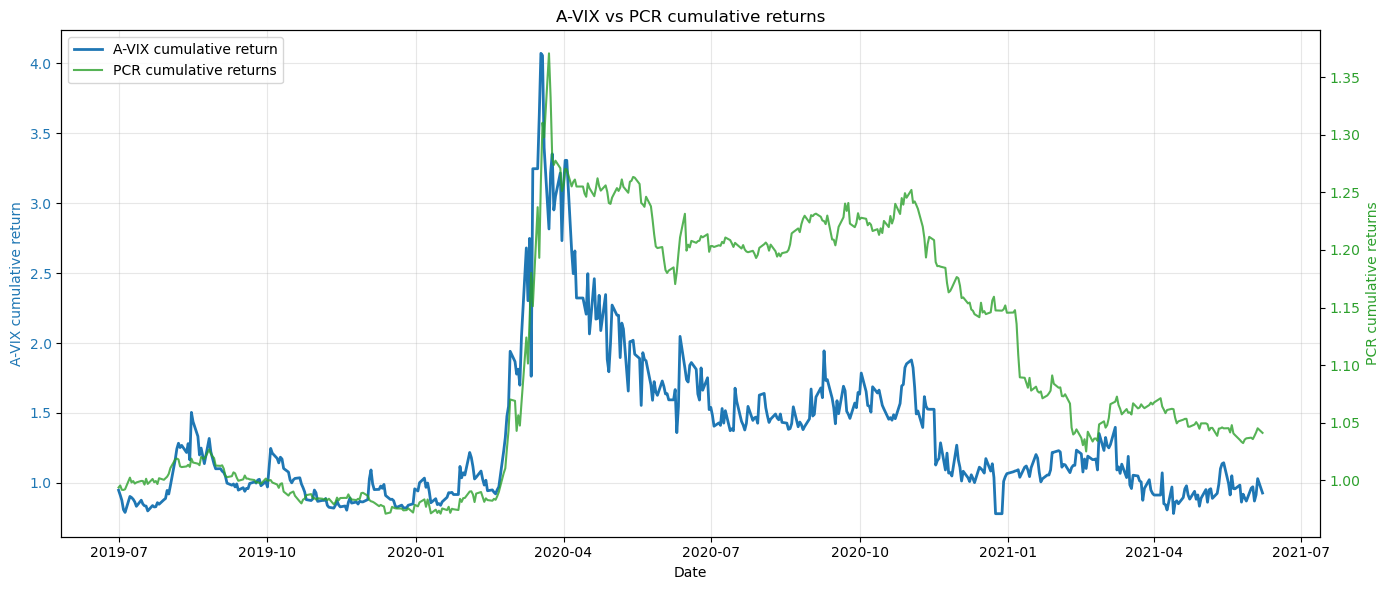

In [7]:
###################
# PCR
###################
TRN_WINDOW = 190
TST_WINDOW = 15
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.06 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 17

y_pred_pcr, y_pred_portfolio_pcr, reconst_pcr, pcr_components, pcr_coeff, pcr_weights, pcr_qp_weights, pcr_trading, gross_returns_pcr = sliding_walk_forward('PCR',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW,ncomponents=N_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pcr)

metrics_portfolio_pcr = compute_tracking_metrics('[PCR] Tracking metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pcr)
metrics_trading_pcr = compute_trading_metrics('[PCR] Trading metrics',pcr_trading,y_pred_portfolio_pcr,gross_returns_pcr,y.iloc[pred_start:pred_end].values)
pcr_objective = compute_objective(y_pred_portfolio_pcr,y.iloc[pred_start:pred_end].values)

if PLOT_GRAPH ==True:
    PLT_STRT = 2000 #0
    PLT_SIZE = 500  #4000
    focused_plot('PCR cumulative returns',y_pred_portfolio_pcr,y.iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)
  

#### **3.2 Partial Least Squares (PLS)**
- Interim results for steps 1-4 in the loop.
- steps 5-10 are not implemented yet.


[PLS] Tracking metrics
------------------------------
Tracking Error (annualised)		: 1.086160
MAE				: 0.044875
RMSE			: 0.068422
TE1 : 0.068431
TE2 : 0.044875
TE3 : 0.051657

[PLS] Trading metrics
------------------------------
Annualised gross returns		: 0.024035
Annualised net returns			: 0.013639
Annualised Transaction Cost		: 0.009003
Annualised Short Borrow Cost	: 0.001392
Annualised Total Cost			: 0.010395
Turnover ratio					: 9.003073
Rebalance days					: 256
Rebalance opportunities			: 257
Number of trades				: 1249
Maximum daily turnover			: 2.000288
Average active holdings			: 4


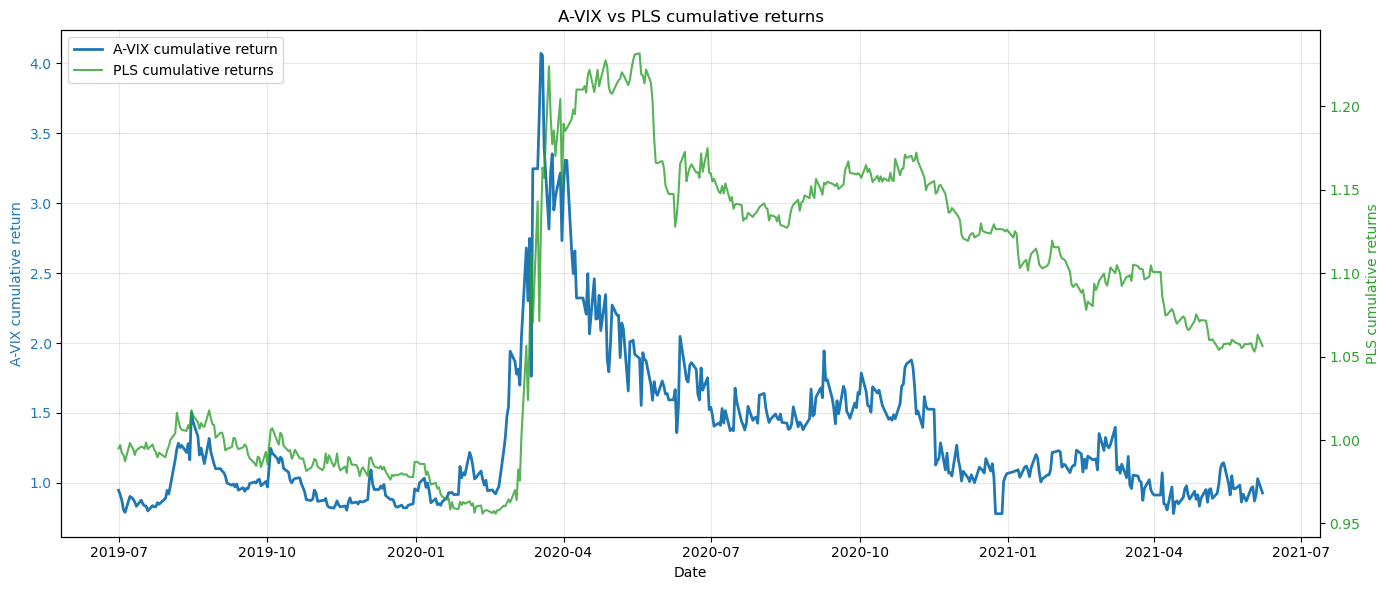

In [8]:
###################
# PLS
###################
TRN_WINDOW = 190
TST_WINDOW = 15
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 5

y_pred_pls, y_pred_portfolio_pls, reconst_pls, pls_components, pls_coeff, pls_weights, pls_qp_weights, pls_trading,gross_returns_pls = sliding_walk_forward('PLS',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW,ncomponents=N_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pls)

metrics_portfolio_pls = compute_tracking_metrics('[PLS] Tracking metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pls)
metrics_trading_pls = compute_trading_metrics('[PLS] Trading metrics',pls_trading,y_pred_portfolio_pls,gross_returns_pls,y.iloc[pred_start:pred_end].values)
pls_objective = compute_objective(y_pred_portfolio_pls,y.iloc[pred_start:pred_end].values)

if PLOT_GRAPH ==True:
    PLT_STRT = 2000 #0
    PLT_SIZE = 500  #4000
    focused_plot('PLS cumulative returns',y_pred_portfolio_pls,y.iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)



#### **3.3 Elastic Net (EN)**
- Interim results for steps 1-4 in the loop.
- steps 5-10 are not implemented yet, step 6 is N/A for EN


[EN] Tracking metrics
------------------------------
Tracking Error (annualised)		: 1.089727
MAE				: 0.045071
RMSE			: 0.068646
TE1 : 0.068655
TE2 : 0.045071
TE3 : 0.051784

[EN] Trading metrics
------------------------------
Annualised gross returns		: 0.011183
Annualised net returns			: 0.002265
Annualised Transaction Cost		: 0.007466
Annualised Short Borrow Cost	: 0.001452
Annualised Total Cost			: 0.008917
Turnover ratio					: 7.465523
Rebalance days					: 257
Rebalance opportunities			: 257
Number of trades				: 2210
Maximum daily turnover			: 1.355305
Average active holdings			: 7


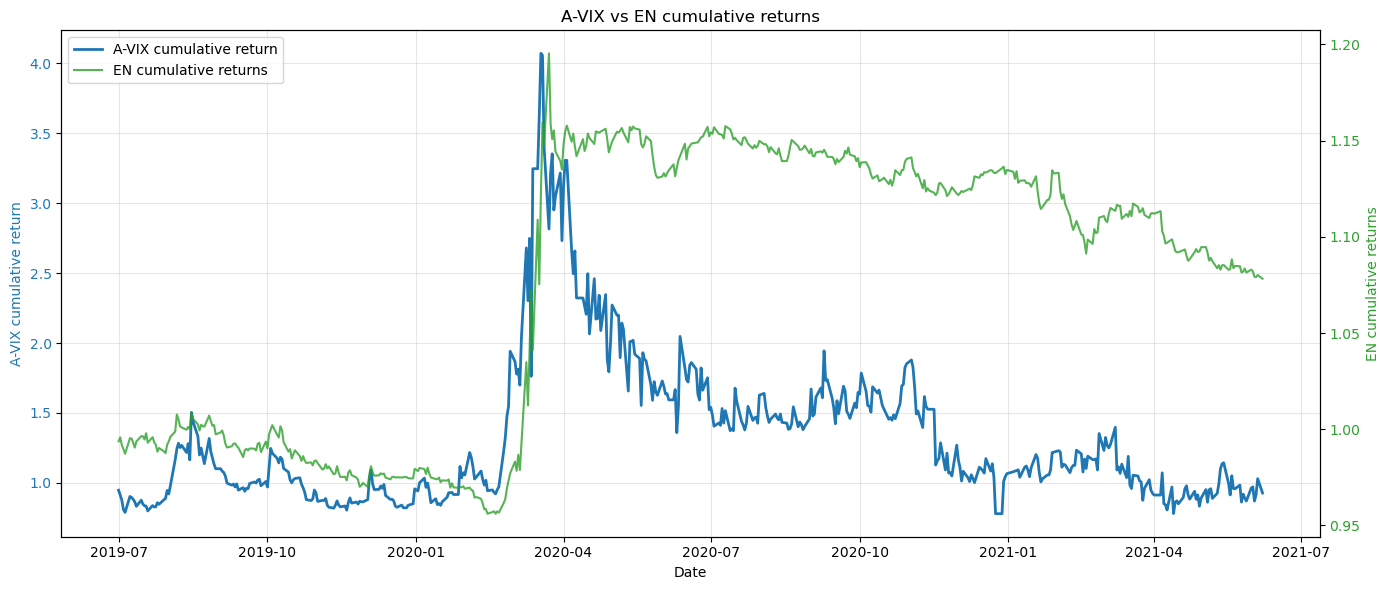

In [9]:
###################
# Elastic Net (EN)
###################
TRN_WINDOW = 190
TST_WINDOW = 15
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.045 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.03 
#N_COMPONENTS = 17

y_pred_en, y_pred_portfolio_en, reconst_en, en_components, en_coeff, en_weights, en_qp_weights, en_trading, gross_returns_en = sliding_walk_forward('EN',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_en)

metrics_portfolio_en = compute_tracking_metrics('[EN] Tracking metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_en)
metrics_trading_en = compute_trading_metrics('[EN] Trading metrics',en_trading,y_pred_portfolio_en,gross_returns_en,y.iloc[pred_start:pred_end].values)
en_objective = compute_objective(y_pred_portfolio_en,y.iloc[pred_start:pred_end].values)

if PLOT_GRAPH ==True:
    PLT_STRT = 2000 #0
    PLT_SIZE = 500  #4000
    focused_plot('EN cumulative returns',y_pred_portfolio_en,y.iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)



### **4. Hidden Markov Model**

Model design steps:
1. Feature engineering for HMM
2. Training a Hidden Markov Model (HMM)
3. Predicting hidden states from emissions
4. Estimating state prediction accuracy (hand label training set again)



In [10]:
# Fady: HMM utils
def train_hmm(emissions,n_states = HMM_STATES, covariance_type="diag", n_iter=100, random_state=SEED):

    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    init_params = "stmc"
    means_init = None
    model = hmm.GaussianHMM(
        n_components=n_states,
        covariance_type=covariance_type,
        n_iter=n_iter,
        random_state=random_state,
        init_params=init_params,
    )

    if means_init is not None:
        model.means_ = means_init

    model.fit(X)

    return model

def predict_states(model, emissions):
    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    states = model.predict(X)

    return states

def reorder_states_by_avix_mean(states,avix_values):
    # Fady: renumber states so state 0 has the lowest A-VIX mean and state HMM_STATES-1 has the highest A-VIX mean.
    states = np.asarray(states)
    avix_values = np.asarray(avix_values)

    state_means = {}

    for state in range(HMM_STATES):
        state_values = avix_values[states == state]

        if len(state_values) > 0:
            state_means[state] = np.mean(state_values)
        else:
            state_means[state] = np.inf

    state_order = sorted(state_means,key=state_means.get)
    state_map = {old_state:new_state for new_state,old_state in enumerate(state_order)}

    reordered_states = np.array([state_map[state] for state in states])

    return reordered_states,state_map

def apply_state_map(states,state_map):
    states = np.asarray(states)
    reordered_states = np.array([state_map[state] for state in states])

    return reordered_states

def evaluate_state_predictions( true_states, predicted_states):
    metrics = {
        "accuracy": accuracy_score(
            true_states,
            predicted_states
        ),
        "precision_macro": precision_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "recall_macro": recall_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "f1_macro": f1_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            true_states,
            predicted_states,
        ),
        "classification_report": classification_report(
            true_states,
            predicted_states,
            zero_division=0,
        ),
    }

    return metrics

def plot_column_histograms( data, bins=50, figsize=(8, 5)):
    if not isinstance(data, pd.DataFrame):
        data = pd.DataFrame(data)

    for col in data.columns:
        plt.figure(figsize=figsize)
        plt.hist(data[col].dropna(), bins=bins, edgecolor="black")
        plt.title(f"Histogram of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.grid(True, alpha=0.3)
        plt.show()

def plot_series_and_states(y, states):
    if isinstance(y,pd.Series):
        dates = y.index
    else:
        dates = np.arange(len(y))

    y = np.asarray(y)
    states = np.asarray(states)

    # Fady: count the number of days on which the state differs from the previous day's state
    state_transitions = int(np.sum(states[1:] != states[:-1]))
    print(f"\n\nNumber of state transitions: {state_transitions}")
    print('\n\n')

    colors = {
        0: "tab:blue",
        1: "tab:orange",
        2: "tab:green"
    }
    colors = {state:colors[state] for state in range(HMM_STATES)}

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Plot continuous line with segment colours determined by state
    if isinstance(dates,pd.DatetimeIndex):
        x_values = mdates.date2num(dates)
        ax1.xaxis_date()
    else:
        x_values = np.asarray(dates,dtype=float)

    segments = np.stack(
        [np.column_stack([x_values[:-1],y[:-1]]),np.column_stack([x_values[1:],y[1:]])],
        axis=1
    )
    segment_colors = [colors.get(state,"black") for state in states[:-1]]

    ax1.add_collection(LineCollection(segments,colors=segment_colors,linewidths=1.5))
    ax1.autoscale_view()

    # Dummy lines for legend
    for state, color in colors.items():
        ax1.plot([], [], color=color, linewidth=2,
                 label=f"Series (State {state})")

    ax1.set_xlabel("Date")
    ax1.set_ylabel("A-VIX")
    ax1.grid(True, alpha=0.3)

    # Secondary axis showing the states
    ax2 = ax1.twinx()

    ax2.step(
        dates,
        states,
        where="post",
        color="grey",
        #color="white",
        linewidth=2,
        alpha=0.8,
        linestyle="dashed",
        label="State Sequence"
    )

    ax2.set_ylabel("State")
    ax2.set_ylim(-0.5, HMM_STATES-0.5)
    ax2.set_yticks(range(HMM_STATES))

    # Combined legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left")

    plt.title(str(HMM_STATES)+"-state HMM model")
    plt.tight_layout()
    plt.show()

def hmm_feature_engineering(prices,returns,n_states):
    # Fady: HMM basic feature engineering, use the two main features A-VIX and ASX 200 index
    df_p = prices.copy()
    df_r = returns.copy()

    clms=['^AXVI', 'STW.AX']
    df_p= df_p[clms]
    # Add returns
    df_p['^AXVI_r'] = df_r['^AXVI']
    df_p['STW.AX_r'] = df_r['STW.AX']

    # Fady: simple labeling of the training set
    # state 0 = low A-VIX, state 1 = medium A-VIX, state 2 = high A-VIX
    df_p['state'] =0

    if n_states == 3:
        df_p.loc[df_p['^AXVI']>13, 'state'] = 1
        df_p.loc[df_p['^AXVI']>17, 'state'] = 2

    if n_states == 2:
        df_p.loc[df_p['^AXVI']>16, 'state'] = 1

    # Add EMAs and rolling stats
    clms=['^AXVI', 'STW.AX','^AXVI_r','state']
    for clm in clms:
        #df_p['ema3_'+clm] = df_p[clm].ewm(span=3, adjust=False).mean()
        #df_p['ema3_'+clm].bfill(inplace=True)
        #df_p['ema3_pct_'+clm] = df_p['ema3_'+clm].pct_change()
        #df_p['ema3_pct_'+clm].bfill(inplace=True)

        # G_M82 fix: df_p[col].bfill(inplace=True) does nothing in pandas 3 (chained assignment)
        df_p['ema10_'+clm] = df_p[clm].ewm(span=10, adjust=False).mean()
        df_p['ema10_'+clm] = df_p['ema10_'+clm].bfill()
        df_p['ema10_pct_'+clm] = df_p['ema10_'+clm].pct_change()
        df_p['ema10_pct_'+clm] = df_p['ema10_pct_'+clm].bfill()

        #df_p['std10_'+clm] = df_p[clm].rolling(window=10).std()
        #df_p['std10_'+clm].bfill(inplace=True)
        #df_p['std10_pct_'+clm] = df_p['std10_'+clm].pct_change()
        #df_p['std10_pct_'+clm].bfill(inplace=True)

        #df_p['std20_'+clm] = df_p[clm].rolling(window=20).std()
        #df_p['std20_'+clm].bfill(inplace=True)
        #df_p['std20_pct_'+clm] = df_p['std20_'+clm].pct_change()
        #df_p['std20_pct_'+clm].bfill(inplace=True)

    # handle unexpected values
    for clm in df_p.columns:
        finite_values = df_p.loc[np.isfinite(df_p[clm]),clm]
        df_p[clm] = df_p[clm].replace(np.inf,finite_values.max())
        df_p[clm] = df_p[clm].replace(-np.inf,finite_values.min())

    # Fady: smoothed version using EMA instead of actual value.
    df_p['state2'] =0
    if n_states == 3:
        df_p.loc[df_p['ema10_^AXVI']>13, 'state2'] = 1
        df_p.loc[df_p['ema10_^AXVI']>17, 'state2'] = 2
    if n_states == 2:
        df_p.loc[df_p['ema10_^AXVI']>17, 'state2'] = 1

    return df_p

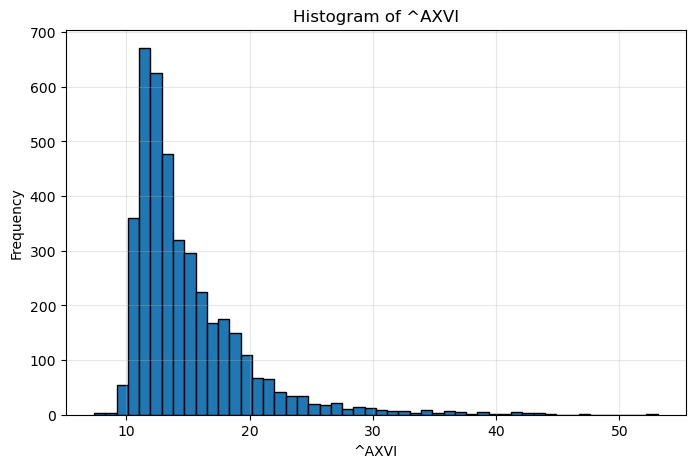

In [11]:
if PLOT_GRAPH ==True:
    plot_column_histograms(screened_prices['^AXVI'])


 HMM accuracy:  0.8464955577492597





{'accuracy': 0.8464955577492597,
 'precision_macro': 0.8441071910372253,
 'recall_macro': 0.84580648262666,
 'f1_macro': 0.844888790605509,
 'confusion_matrix': array([[1578,  213,    0],
        [ 176, 1042,  120],
        [   0,  113,  810]]),
 'classification_report': '              precision    recall  f1-score   support\n\n           0       0.90      0.88      0.89      1791\n           1       0.76      0.78      0.77      1338\n           2       0.87      0.88      0.87       923\n\n    accuracy                           0.85      4052\n   macro avg       0.84      0.85      0.84      4052\nweighted avg       0.85      0.85      0.85      4052\n'}






Number of state transitions: 156





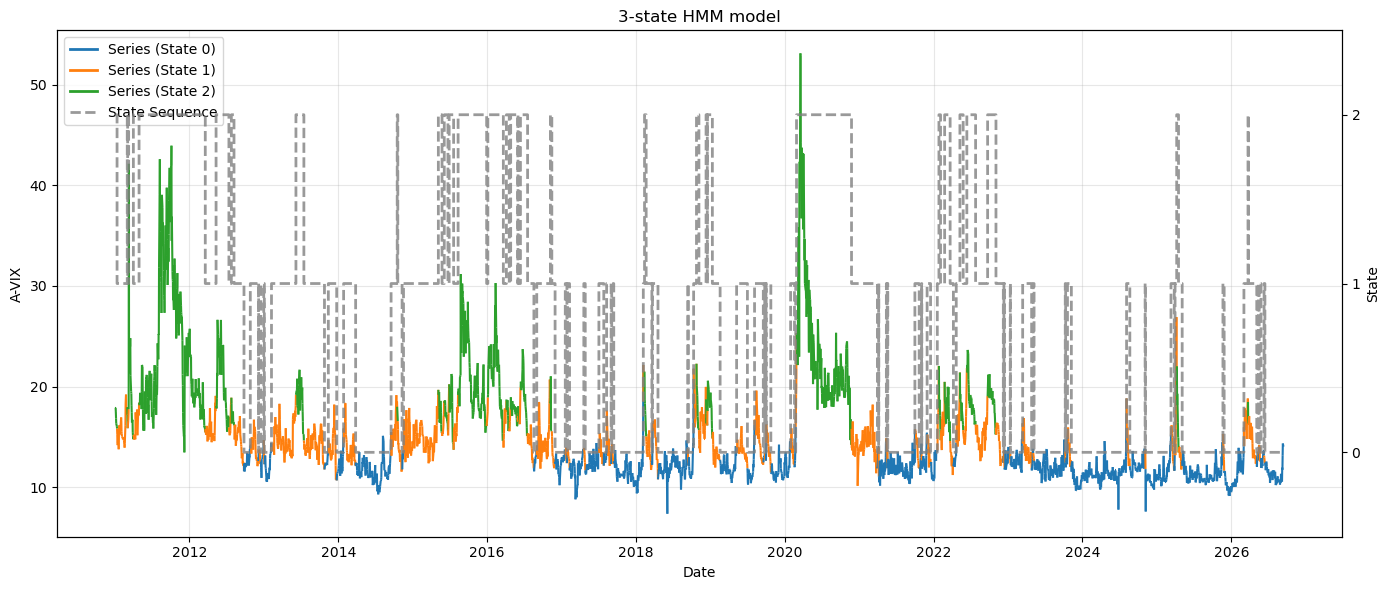

In [12]:

np.random.seed(SEED)
df_p = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)
hmm_features=['state2','ema10_state','^AXVI','ema10_^AXVI']


# HMM modeling
hmm_baseline_model = train_hmm( emissions=df_p[hmm_features], n_states=HMM_STATES )
predicted_states = predict_states(  hmm_baseline_model,  df_p[hmm_features] )
predicted_states,state_map = reorder_states_by_avix_mean(predicted_states,df_p['^AXVI'].values)
df_p['pred_state'] = predicted_states


hmm_metrics = evaluate_state_predictions(
    df_p['state'].values,
    df_p['pred_state'].values
)

print('\n HMM accuracy: ', hmm_metrics['accuracy'])
print('\n\n')
display(hmm_metrics)
print('\n\n')

if PLOT_GRAPH ==True:
    plot_series_and_states(df_p['^AXVI'], df_p['pred_state'])

### **5. Expanding window Walk-forward loop for HMM**

1. Generate the train and test pairs for each iteration.
2. Fit the HMM model on the training window data
3. Apply state based EN (or PCR, PLS) fiting to training window
4. Predict the test window HMM states
5. Predict A-VIX percentage change
6. Reconstruct the A-VIX level from the predicted precentage change
7. Calculate different tracking error metrics on test window.
8. Calculate the state-based individual securties coeffcients from the factor coefficents.
9. Define state-based portfolio weight constraints guided by the regressions coeffcients after normalisation.
10. Conduct state-based QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
11. Predict portfolio returns over the test window
12. Calculate trading metrics for the rebalancing at the end of the test window

In [13]:
def expanding_hmm_states(hmm_emissions,initial_train_window_size,test_window_size):
    hmm_states = []
    splits=walk_forward_expanding_window(len(hmm_emissions), initial_train_window_size, test_window_size)
    for split in splits.itertuples():

        hmm_train = hmm_emissions[split.train_start:split.train_end + 1]
        hmm_test  = hmm_emissions[split.test_start:split.test_end + 1]

        hmm_model = train_hmm(hmm_train,n_states=HMM_STATES)
        train_states = predict_states(hmm_model,hmm_train)
        test_states = predict_states(hmm_model,hmm_test)

        # Fady: determine the state order from A-VIX smoother means in the training
        # window only and apply the same state mapping to the test window.
        train_states,state_map = reorder_states_by_avix_mean(
            #train_states,hmm_train['^AXVI'].values
            train_states,hmm_train['ema10_^AXVI'].values
        )
        test_states = apply_state_map(test_states,state_map)
        hmm_states.append((train_states,test_states))

    return hmm_states


# Fady: expanding window loop with HMM state based models
def expanding_walk_forward(title,X_df,y_df,orig_price,hmm_states,initial_train_window_size,test_window_size,ncomponents=None):

    if ncomponents is None:
        ncomponents = N_COMPONENTS

    y_pred = []
    y_pred_portfolio = [] # net portfolio returns (after costs)
    y_pred_portfolio_gross = [] # gross portfolio returns
    pred_states = []
    pcr_ncomponents = []
    trading_records = []
    previous_qp_weights = None
    previous_state = None

    splits=walk_forward_expanding_window(len(X_df), initial_train_window_size, test_window_size)

    if len(hmm_states) != len(splits):
        raise ValueError("hmm_states must contain one entry per expanding-window split.")

    for split,(train_states,test_states) in zip(splits.itertuples(),hmm_states):
        X_train = X_df[split.train_start:split.train_end + 1]
        y_train = y_df[split.train_start:split.train_end + 1]
        X_test  = X_df[split.test_start:split.test_end + 1]

        ypred = np.zeros(len(X_test))
        qp_weights_by_state = {}

        for state in range(HMM_STATES):
            train_mask = train_states == state
            test_mask = test_states == state

            if not np.any(test_mask):
                continue

            X_train_state = X_train.iloc[train_mask]
            y_train_state = y_train.iloc[train_mask]
            X_test_state = X_test.iloc[test_mask]

            # ElasticNetCV needs at least 3 observations for cv=3.
            # Use the expanding training set only if a state is too small.
            if len(X_train_state) < 3:
                X_train_state = X_train
                y_train_state = y_train

            # window_key identifies the state's training and test rows for the fit cache
            window_key = ('expanding',HMM_STATES,split.train_start,split.train_end,split.test_start,split.test_end,state,
                          hash(train_mask.tobytes()),hash(test_mask.tobytes()))

            state_pred,ncomponents_used,coefficients,portfolio_weights,qp_weights = fit_qp_portfolio(
                title,X_train_state,y_train_state,X_test_state,ncomponents,window_key
            )

            if ncomponents_used is not None:
                pcr_ncomponents.append(ncomponents_used)

            qp_weights_by_state[state] = qp_weights.copy()
            ypred[test_mask] = state_pred

        # Fady: newly estimated QP weights for each test day (those of the day's state)
        qp_columns = list(qp_weights.columns)
        daily_qp_weights = np.zeros((len(X_test),len(qp_columns)))

        for state,state_qp_weights in qp_weights_by_state.items():
            daily_qp_weights[test_states == state] = state_qp_weights.iloc[0].values

        # Fady: the portfolio only changes on a regime switch: the state differs from the previous
        # day's state (the first day is compared with the last state of the previous window, and
        # the very first portfolio is always built). Otherwise the current weights are kept.
        rebalance_opportunities = np.r_[
            previous_qp_weights is None or test_states[0] != previous_state,
            test_states[1:] != test_states[:-1]
        ]

        executed_qp_weights = np.zeros((len(X_test),len(qp_columns)))
        current_weights = None if previous_qp_weights is None else previous_qp_weights.iloc[-1].values

        for day in range(len(X_test)):
            if rebalance_opportunities[day]:
                current_weights = daily_qp_weights[day]
            executed_qp_weights[day] = current_weights

        executed_qp_weights = pd.DataFrame(executed_qp_weights,index=X_test.index,columns=qp_columns)

        trading,ypred_portfolio,ypred_portfolio_gross = trade_portfolio(
            executed_qp_weights,previous_qp_weights,X_test,rebalance_opportunities
        )
        trading_records.append(trading)

        previous_qp_weights = executed_qp_weights.iloc[[-1]].copy()
        previous_state = test_states[-1]

        y_pred.extend(list(ypred))
        y_pred_portfolio.extend(list(ypred_portfolio))
        y_pred_portfolio_gross.extend(list(ypred_portfolio_gross))
        pred_states.extend(list(test_states))

    reconst = walk_forward_reconst(y_pred_portfolio,orig_price,splits)

    trading_records = pd.concat(trading_records)

    return y_pred, y_pred_portfolio, reconst, pcr_ncomponents, pred_states, coefficients, portfolio_weights, qp_weights, trading_records,y_pred_portfolio_gross




[PCR_HMM] Tracking metrics
------------------------------
Tracking Error (annualised)		: 1.066263
MAE				: 0.044430
RMSE			: 0.067168
TE1 : 0.067177
TE2 : 0.044430
TE3 : 0.050381

[PCR_HMM] Trading metrics
------------------------------
Annualised gross returns		: -0.006422
Annualised net returns			: -0.022150
Annualised Transaction Cost		: 0.014327
Annualised Short Borrow Cost	: 0.001402
Annualised Total Cost			: 0.015729
Turnover ratio					: 14.326723
Rebalance days					: 159
Rebalance opportunities			: 159
Number of trades				: 1998
Maximum daily turnover			: 1.741920
Average active holdings			: 8


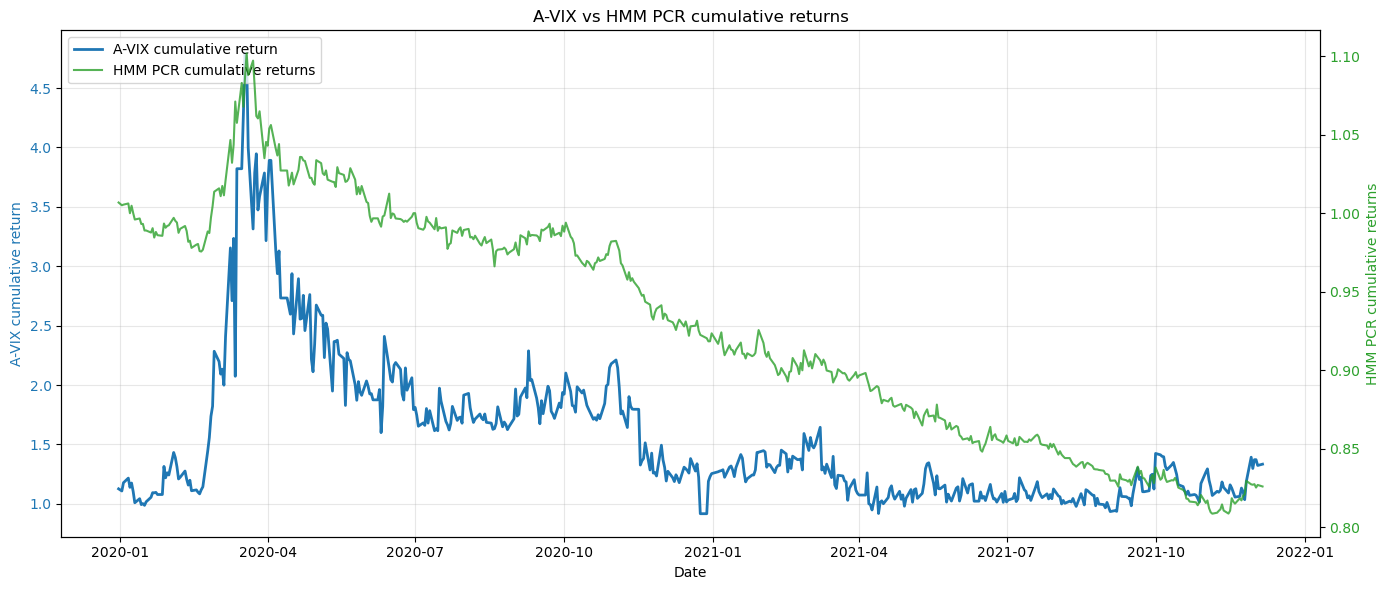

In [14]:
#########################
# Expanding HMM + PCR
#########################

TRN_WINDOW = 320
TST_WINDOW = 55
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.04 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 17

hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

y_pred_pcr_exp, y_pred_portfolio_pcr_exp, reconst_pcr_exp, pcr_components_exp, pred_states_pcr_exp, hmm_pcr_coeff, hmm_pcr_weights, hmm_pcr_qp_weights, hmm_pcr_trading, gross_returns_pcr_exp = expanding_walk_forward(
    'PCR',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW,N_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pcr_exp)

metrics_portfolio_pcr_exp = compute_tracking_metrics('[PCR_HMM] Tracking metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pcr_exp)
metrics_trading_pcr_exp = compute_trading_metrics('[PCR_HMM] Trading metrics',hmm_pcr_trading,y_pred_portfolio_pcr_exp,gross_returns_pcr_exp,y.iloc[pred_start:pred_end].values)
pcr_exp_objective = compute_objective(y_pred_portfolio_pcr_exp,y.iloc[pred_start:pred_end].values)

if PLOT_GRAPH ==True:
    PLT_STRT = 2000 #0
    PLT_SIZE = 500  #4000
    focused_plot('HMM PCR cumulative returns',y_pred_portfolio_pcr_exp,y.iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)

  


[PLS_HMM] Tracking metrics
------------------------------
Tracking Error (annualised)		: 1.082565
MAE				: 0.044756
RMSE			: 0.068195
TE1 : 0.068204
TE2 : 0.044756
TE3 : 0.051460

[PLS_HMM] Trading metrics
------------------------------
Annualised gross returns		: 0.006104
Annualised net returns			: -0.009126
Annualised Transaction Cost		: 0.013635
Annualised Short Borrow Cost	: 0.001595
Annualised Total Cost			: 0.015230
Turnover ratio					: 13.634648
Rebalance days					: 150
Rebalance opportunities			: 150
Number of trades				: 1648
Maximum daily turnover			: 1.903604
Average active holdings			: 7


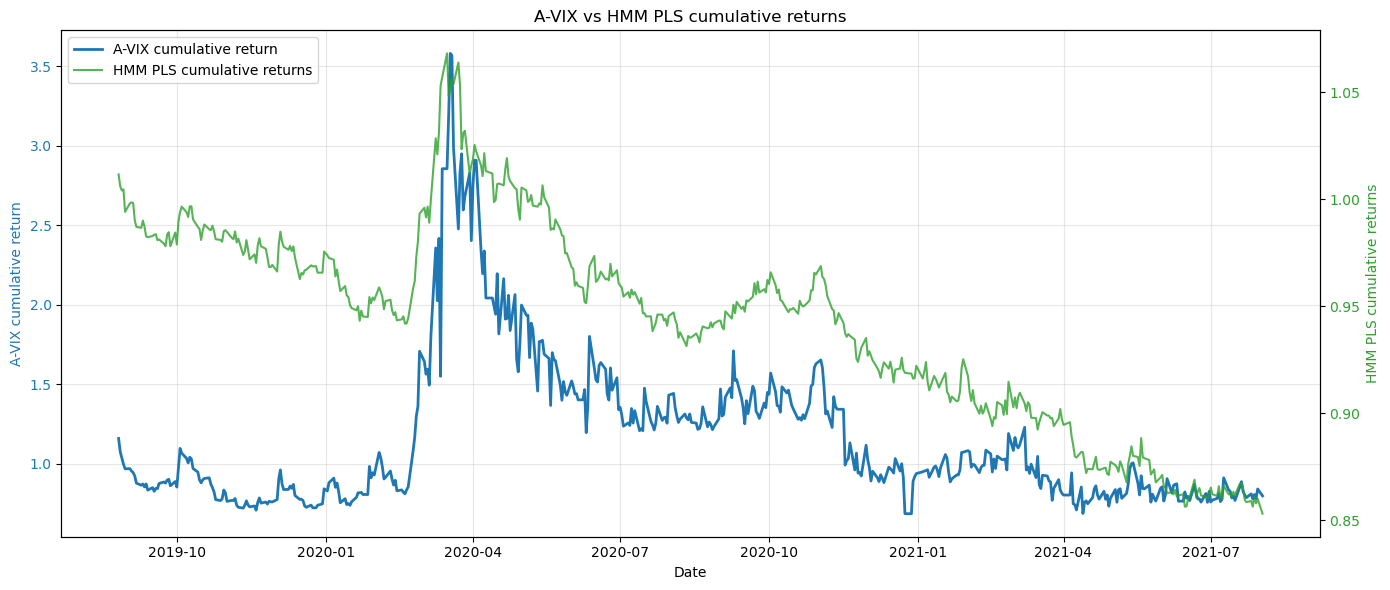

In [15]:
#########################
# Expanding HMM + PLS
#########################
TRN_WINDOW = 230
TST_WINDOW = 63
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.04 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.04 
N_COMPONENTS = 6

hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

pls_ncomponents_exp = N_COMPONENTS
y_pred_pls_exp, y_pred_portfolio_pls_exp, reconst_pls_exp, pls_components_exp, pred_states_pls_exp, hmm_pls_coeff, hmm_pls_weights, hmm_pls_qp_weights, hmm_pls_trading, gross_returns_pls_exp = expanding_walk_forward(
    'PLS',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW,pls_ncomponents_exp)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pls_exp)

metrics_portfolio_pls_exp = compute_tracking_metrics('[PLS_HMM] Tracking metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pls_exp)
metrics_trading_pls_exp = compute_trading_metrics('[PLS_HMM] Trading metrics',hmm_pls_trading,y_pred_portfolio_pls_exp,gross_returns_pls_exp,y.iloc[pred_start:pred_end].values)
pls_exp_objective = compute_objective(y_pred_portfolio_pls_exp,y.iloc[pred_start:pred_end].values)

if PLOT_GRAPH ==True:
    PLT_STRT = 2000 #0
    PLT_SIZE = 500  #4000
    focused_plot('HMM PLS cumulative returns',y_pred_portfolio_pls_exp,y.iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)




[EN_HMM] Tracking metrics
------------------------------
Tracking Error (annualised)		: 1.078633
MAE				: 0.044579
RMSE			: 0.067947
TE1 : 0.067956
TE2 : 0.044579
TE3 : 0.051286

[EN_HMM] Trading metrics
------------------------------
Annualised gross returns		: -0.000027
Annualised net returns			: -0.014964
Annualised Transaction Cost		: 0.013094
Annualised Short Borrow Cost	: 0.001843
Annualised Total Cost			: 0.014937
Turnover ratio					: 13.094140
Rebalance days					: 146
Rebalance opportunities			: 146
Number of trades				: 823
Maximum daily turnover			: 2.000191
Average active holdings			: 3


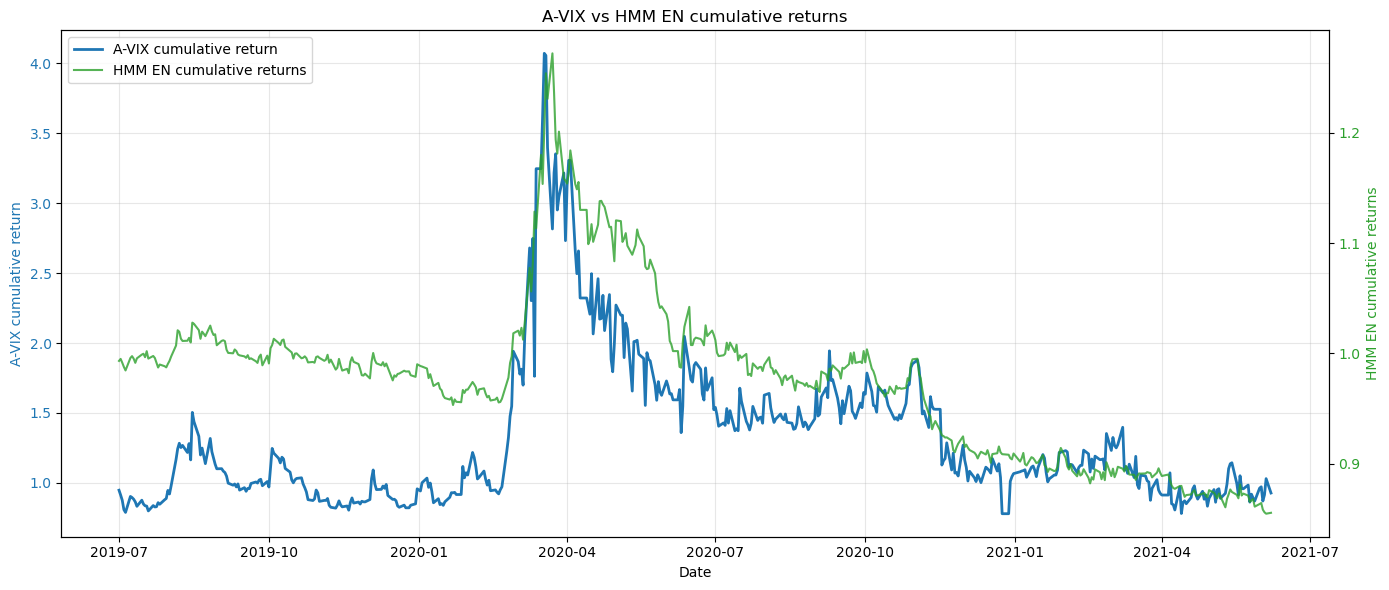

In [16]:
#########################
# Expanding HMM + Elastic Net
#########################
TRN_WINDOW = 190
TST_WINDOW = 63
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.07 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.05 
#N_COMPONENTS = 17

hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

y_pred_en_exp, y_pred_portfolio_en_exp, reconst_en_exp, en_components_exp, pred_states_en_exp, hmm_en_coeff, hmm_en_weights, hmm_en_qp_weights, hmm_en_trading, gross_returns_en_exp = expanding_walk_forward(
    'EN',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_en_exp)

metrics_portfolio_en_exp = compute_tracking_metrics('[EN_HMM] Tracking metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_en_exp)
metrics_trading_en_exp = compute_trading_metrics('[EN_HMM] Trading metrics',hmm_en_trading,y_pred_portfolio_en_exp,gross_returns_en_exp,y.iloc[pred_start:pred_end].values)
en_exp_objective = compute_objective(y_pred_portfolio_en_exp,y.iloc[pred_start:pred_end].values)

if PLOT_GRAPH ==True:
    PLT_STRT = 2000 #0
    PLT_SIZE = 500  #4000
    focused_plot('HMM EN cumulative returns',y_pred_portfolio_en_exp,y.iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)
  



### **6. Randomized grid search**
1. Construct grid search space
2. For each set the six algorithms are evaluated and the objectives are calculated: pcr_objective, pls_objective, en_objective, pcr_exp_objective, pls_exp_objective, en_exp_objective.
3. Every time one of the six objectives reaches a new maximum, record it in a log file with the corresponding parameters

